# Coterminal scheme arrows

Two arrows that share the same terminals (A→B plus B→A, or two A→B) used to fling one shaft. Layout now **groups** them, solves **one centerline**, then **miter-offsets** lanes so they stay a constant distance along the whole path.

`mol("CCO") >> mol("CC=O")` only adds **one** edge. Use `pair(...)` below for two or more.

**Restart kernel** after `make build-python` / `make agent-install` so this notebook sees the native ext.


In [1]:
from __future__ import annotations

from xpict import mol
from xpict.spec import DepictSpec


def pair(
    *arrows: tuple[str, str],
    a: str = "CCO",
    b: str = "CC=O",
    names: tuple[str | None, str | None] = ("ethanol", "acetaldehyde"),
    labels: list[str | None] | None = None,
    colors: list[str | None] | None = None,
    **layout,
) -> DepictSpec:
    """Two-mol scheme. Each arrow is `("A", "B")` or `("B", "A")`."""
    children: list[dict] = [
        mol(a, id="A", name=names[0]).to_node().model_dump(exclude_none=True),
        mol(b, id="B", name=names[1]).to_node().model_dump(exclude_none=True),
    ]
    for i, (src, tgt) in enumerate(arrows):
        edge: dict = {"type": "edge", "sources": src, "targets": tgt, "arrow": "forward"}
        if colors and i < len(colors) and colors[i]:
            edge["color"] = colors[i]
        if labels and i < len(labels) and labels[i]:
            lid = f"lab{i}"
            children.append({"type": "text", "id": lid, "text": labels[i]})
            edge["label"] = {"id": lid, "pos": "above" if i % 2 == 0 else "below"}
        children.append(edge)
    spec: dict = {"type": "reaction_scheme", "children": children}
    if layout:
        spec["layout"] = layout
    return DepictSpec.model_validate(spec)


## 1 · Single A→B (baseline)

One shaft. Sugar `mol(...) >> mol(...)` does the same thing.


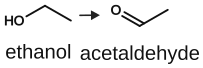

In [2]:
pair(("A", "B"))


## 2 · A→B and B→A (the old fling)

Same terminals, opposite direction. Black is A→B, red is B→A. They should sit on parallel lanes, not one flung off-page.


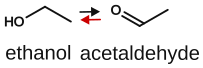

In [3]:
pair(("A", "B"), ("B", "A"), colors=["#111", "#c00"])


## 3 · Two forward A→B

Same direction, same terminals — also grouped and offset.


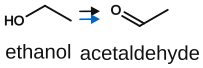

In [4]:
pair(("A", "B"), ("A", "B"), colors=["#111", "#06c"])


## 4 · Three lanes + labels

Add or drop arrows in the `pair(...)` call. Labels ride above / below alternating.


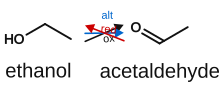

In [5]:
pair(
    ("A", "B"),
    ("A", "B"),
    ("B", "A"),
    colors=["#111", "#06c", "#c00"],
    labels=["ox", "alt", "red"],
)


## 5 · Knobs

Try `direction` (`right` / `down`), `edge_routing` (`polyline` / `orthogonal` / `splines`), different SMILES.


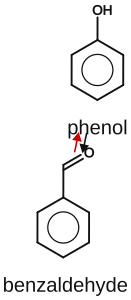

In [6]:
pair(
    ("A", "B"),
    ("B", "A"),
    a="c1ccccc1O",
    b="c1ccccc1C=O",
    names=("phenol", "benzaldehyde"),
    colors=["#111", "#c00"],
    direction="down",
    edge_routing="polyline",
)
